# TV Cleaner: what changed on a Google TV, in data

A TCL Google TV (Android 12, 2 GB of RAM) was cleaned up and given a new home screen over four days. This notebook
looks at the data collected along the way:

1. **How the TV was used before** anything changed (`usage_before.csv`).
2. **What was changed:** packages turned off, back on, installed and removed (`changes.csv`).
3. **What it did to performance:** free memory and frame times (`performance.csv`).
4. **Where it stands now:** the latest snapshot from the collector (`snapshots_*.csv`).

All data is anonymized: dates are *day N* (day 1 = the day the cleanup started) and screen time is each app's share
of the total, not hours.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt

plt.rcParams.update({"figure.figsize": (9, 4.5), "axes.spines.top": False, "axes.spines.right": False})
D = "../datasets/"
apps = pd.read_csv(D + "apps.csv")
before = pd.read_csv(D + "usage_before.csv").merge(apps, on="package", how="left")
changes = pd.read_csv(D + "changes.csv").merge(apps, on="package", how="left")
perf = pd.read_csv(D + "performance.csv")
system = pd.read_csv(D + "snapshots_system.csv")
pkgs = pd.read_csv(D + "snapshots_packages.csv").merge(apps, on="package", how="left")
now = pd.read_csv(D + "snapshots_usage.csv").merge(apps, on="package", how="left")

## 1. Before: where the screen time went

In [2]:
before[["name", "category", "screen_share_pct", "launch_share_pct"]].head(10)

,name,category,screen_share_pct,launch_share_pct
0,Netflix,Streaming,42.40,10.49
1,YouTube,Streaming,34.44,9.97
2,Prime Video,Streaming,12.75,3.84
3,Disney+,Streaming,2.93,1.79
4,Google TV home,Home screen,2.51,35.29
5,Ambient mode,Home screen,2.07,4.86
6,Settings,Settings,0.77,12.28
7,Screen mirroring,Tools,0.77,0.51
8,Stremio,Streaming,0.40,1.28
9,TV inputs,Tools,0.23,0.51


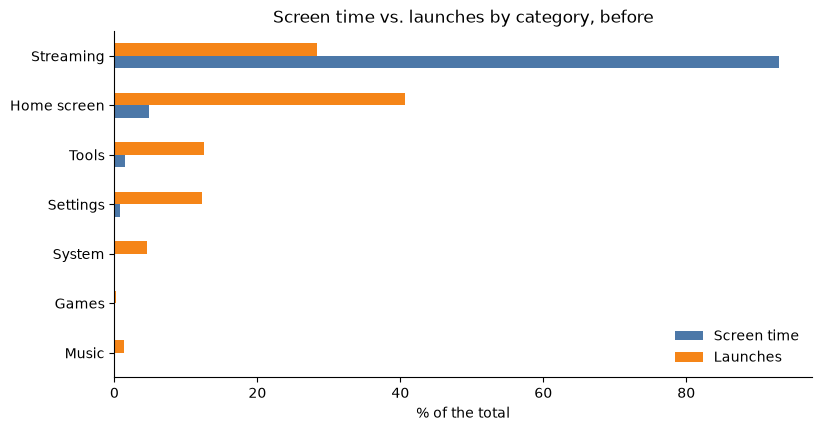

In [3]:
by_cat = before.groupby("category")[["screen_share_pct", "launch_share_pct"]].sum().sort_values("screen_share_pct")
ax = by_cat.plot.barh(color=["#4C78A8", "#F58518"])
ax.set(xlabel="% of the total", ylabel="", title="Screen time vs. launches by category, before")
ax.legend(["Screen time", "Launches"], frameon=False)
plt.show()

Three streaming apps hold almost 90% of the screen time. The Google TV home screen gets only a small slice of
the time but more than a third of the launches: it is the place people pass through on their way to something
else, so it's the one screen worth making fast and ad-free.

In [4]:
used = set(before.loc[before["screen_share_pct"] > 0, "package"])
bloat = apps[apps["category"] == "Bloat"]
print(f"Pre-installed extras: {len(bloat)}, of which ever used: {len(used & set(bloat['package']))}")

Pre-installed extras: 15, of which ever used: 0


## 2. What was changed

In [5]:
summary = changes.groupby(["round", "action"]).size().unstack(fill_value=0)
summary

action,disabled,enabled,installed,uninstalled
round,,,,
factory,1,0,0,0
home screen,4,1,1,0
music,0,1,1,0
round 1,17,1,0,0
round 2,5,0,1,1


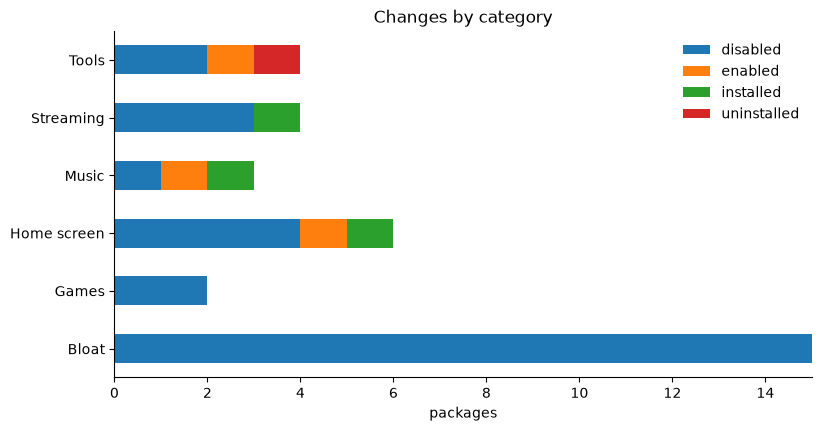

In [6]:
ax = changes.groupby(["category", "action"]).size().unstack(fill_value=0).plot.barh(stacked=True)
ax.set(xlabel="packages", ylabel="", title="Changes by category")
ax.legend(frameon=False)
plt.show()

Nothing was uninstalled from the system: extras were only *disabled* (`pm disable-user`), so each change can
be undone with one command. The one app uninstalled was installed by the user.

## 3. Performance

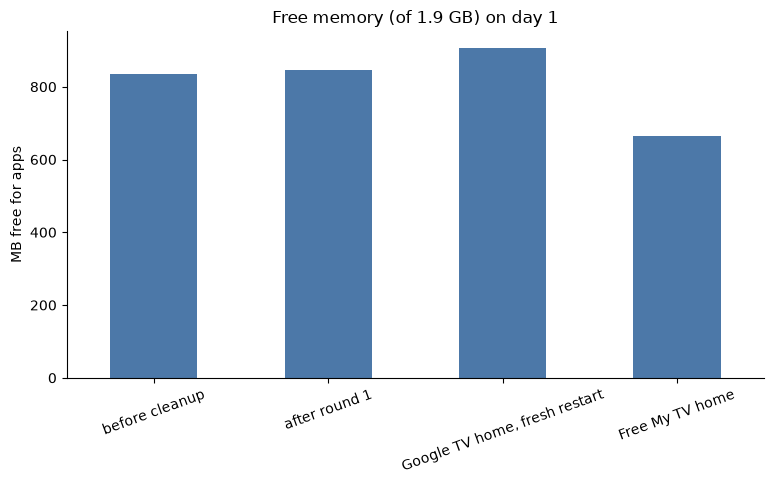

In [7]:
mem = perf[perf["metric"] == "mem_available_mb"]
ax = mem.plot.bar(x="stage", y="value", legend=False, color="#4C78A8", rot=20)
ax.set(ylabel="MB free for apps", xlabel="", title="Free memory (of 1.9 GB) on day 1")
plt.show()

Disabling the extras freed only about 11 MB: disabled apps that weren't running don't use memory. The custom
home screen costs memory (a full illustrated, animated scene), which the next charts show was then reined in.

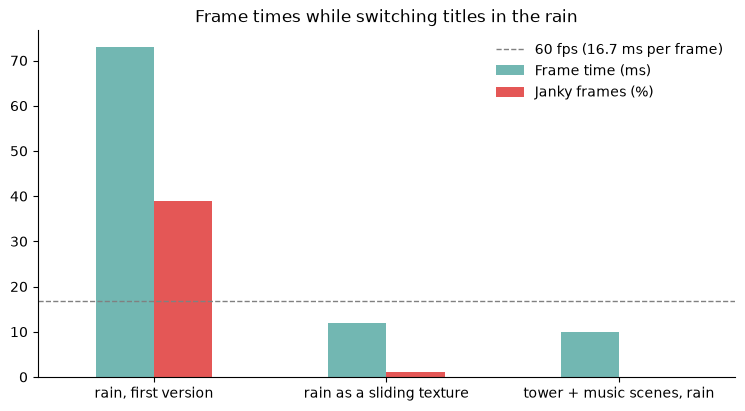

In [8]:
fr = perf[perf["metric"].isin(["janky_pct", "frame_ms"])].pivot_table(index="stage", columns="metric", values="value", sort=False)
fr = fr[["frame_ms", "janky_pct"]].rename(columns={"frame_ms": "Frame time (ms)", "janky_pct": "Janky frames (%)"})
ax = fr.plot.bar(rot=0, color=["#72B7B2", "#E45756"])
ax.axhline(16.7, ls="--", c="gray", lw=1, label="60 fps (16.7 ms per frame)")
ax.set(xlabel="", title="Frame times while switching titles in the rain")
ax.legend(frameon=False)
plt.show()

The first version of the rain made 39% of frames late (about 73 ms each, under 14 fps). Drawing the rain as a
ready-made texture that slides, and holding the sky still while titles move, brought it to 1%; the final version
with the tower and music scenes renders every frame in about 10 ms.

## 4. Now: the latest snapshot

In [9]:
system.T

,0
day,4
home_app,io.freemytv
storage_used_pct,47
packages,152
packages_disabled,25
packages_user,12
frames,22091
janky_pct,0.53
frame_p50_ms,10
frame_p90_ms,19


In [10]:
state = pkgs[pkgs["day"] == pkgs["day"].max()]
print(state.groupby(["category", "enabled"]).size().unstack(fill_value=0))

enabled      no  yes
category            
Bloat        15    0
Games         2    1
Home screen   3    2
Music         1    1
Settings      0    1
Streaming     3    6
System        0  109
Tools         1    7


In [11]:
# Does the TV match the changes log? Every package whose last logged action was "disabled" should be off.
last = changes.sort_values("day").groupby("package").last()
expect_off = set(last[last["action"] == "disabled"].index)
expect_on = set(last[last["action"] == "enabled"].index)
off = set(state.loc[state["enabled"] == "no", "package"])
print("Logged as off but on now:", sorted(expect_off - off) or "none")
print("Logged as back on but off now:", sorted(expect_on & off) or "none")
print("Off now but not in the log:", sorted(off - expect_off - expect_on) or "none")

Logged as off but on now: none
Logged as back on but off now: ['com.google.android.youtube.tvmusic']
Off now but not in the log: none


This check is what the collector is for: run it now and then (`python collector/collect.py <TV IP>`), and the
log of changes and the TV's real state can be compared, and drift (a system update turning something back on, or a
change nobody wrote down) shows up here.